# What is wrong with the Challenger joints analysis?

The original analysis says: *"temperature has no effect, so the launch is safe."*
This notebook shows that this conclusion is wrong, because of **3 mistakes**:

1. The flights **with no failure were removed**.
2. **No confidence interval** was shown, and 31°F is far outside the tested temperatures.
3. The **final calculation** is wrong (and ignores temperature).

## 0. The data
Rebuilt from the table in the notebook of the exercise

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

data = pd.DataFrame({
    "Temperature": [66,70,69,68,67,72,73,70,57,63,70,78,67,53,67,75,70,81,76,79,75,76,58],
    "Malfunction": [0,1,0,0,0,0,0,0,1,1,1,0,0,2,0,0,0,0,0,0,2,0,1],
})
data["Count"] = 6                                  # 6 joints per flight
data["Frequency"] = data.Malfunction / data.Count  # fraction of joints that failed
data["Success"] = data.Count - data.Malfunction    # joints that did not fail
data["Intercept"] = 1

only_failures = data[data.Malfunction > 0]         # what the original analysis kept
data.head()

,Temperature,Malfunction,Count,Frequency,Success,Intercept
0,66,0,6,0.000000,6,1
1,70,1,6,0.166667,5,1
2,69,0,6,0.000000,6,1
3,68,0,6,0.000000,6,1
4,67,0,6,0.000000,6,1


## Mistake 1: removing the flights with no failure

The original analysis claims that the flights with no failure "bring no information". That is false because a warm flight with no failure is exactly the proof that warm weather is safe.
If we only keep the flights where some joints broke, we cannot see any link with temperature.

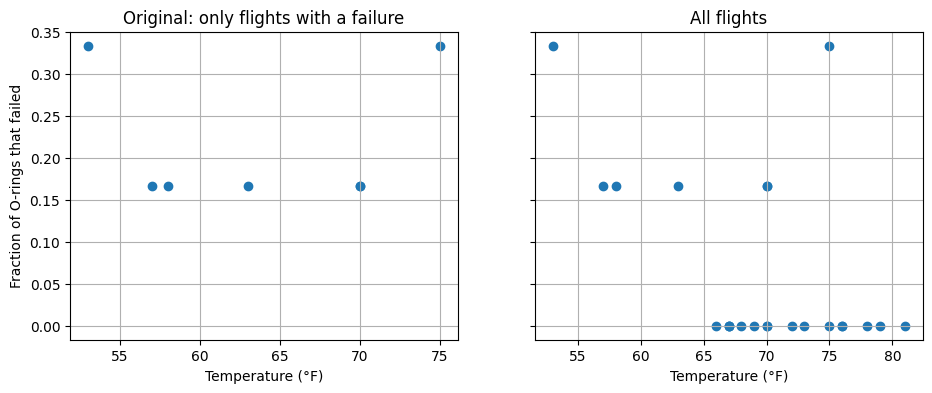

In [8]:
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

left.scatter(only_failures.Temperature, only_failures.Frequency)
left.set_title("Original: only flights with a failure")

right.scatter(data.Temperature, data.Frequency)
right.set_title("All flights")

for ax in (left, right):
    ax.set_xlabel("Temperature (°F)")
    ax.grid(True)
left.set_ylabel("Fraction of O-rings that failed")
plt.show()

In [12]:
cold = data[data.Temperature < 65]
warm = data[data.Temperature >= 65]

print("Cold flights (< 65°F):", len(cold), "flights,", (cold.Malfunction > 0).sum(), "had a failure")
print("Warm flights (>= 65°F):", len(warm), "flights,", (warm.Malfunction > 0).sum(), "had a failure")

Cold flights (< 65°F): 4 flights, 4 had a failure
Warm flights (>= 65°F): 19 flights, 3 had a failure


**All** the cold flights had a failure, but only a few warm ones did. We cannot see this if we remove the zeros.

## Mistake 2: no confidence interval

We fit a logistic regression (same idea as the original), but now:
* on **all** the flights,
* with the response given as *(failures, successes)* for the 6 joints (this is the correct way to say "6 trials per flight"),
* and we draw the **95% confidence interval**.

In [15]:
cols = ["Intercept", "Temperature"]
family = sm.families.Binomial()

# Model with all flights
model_all = sm.GLM(data[["Malfunction", "Success"]], data[cols], family=family).fit()

# Model like the original analysis (only flights with a failure)
model_orig = sm.GLM(only_failures[["Malfunction", "Success"]], only_failures[cols], family=family).fit()

print("Slope with all flights      :", round(model_all.params["Temperature"], 3),
      " p-value:", round(model_all.pvalues["Temperature"], 3))
print("Slope with only failures    :", round(model_orig.params["Temperature"], 3),
      " p-value:", round(model_orig.pvalues["Temperature"], 3))

Slope with all flights      : -0.116  p-value: 0.014
Slope with only failures    : 0.001  p-value: 0.977


With all flights the slope is **negative** and significant (p-value < 0.05): the colder it is, the more failures.
With only the failures, the slope is about 0, which is the original (wrong) conclusion.

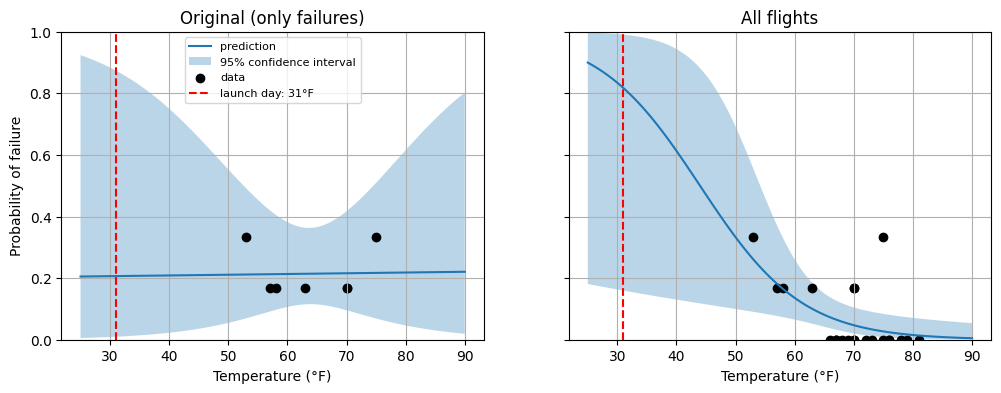

In [17]:
temps = pd.DataFrame({"Intercept": 1, "Temperature": np.linspace(25, 90, 100)})

fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

for ax, model, points, title in [
    (left,  model_orig, only_failures, "Original (only failures)"),
    (right, model_all,  data,          "All flights"),
]:
    pred = model.get_prediction(temps).summary_frame()
    ax.plot(temps.Temperature, pred["mean"], label="prediction")
    ax.fill_between(temps.Temperature, pred["mean_ci_lower"], pred["mean_ci_upper"],
                    alpha=0.3, label="95% confidence interval")
    ax.scatter(points.Temperature, points.Frequency, color="black", label="data")
    ax.axvline(31, color="red", linestyle="--", label="launch day: 31°F")
    ax.set_title(title)
    ax.set_xlabel("Temperature (°F)")
    ax.set_ylim(0, 1)
    ax.grid(True)

left.set_ylabel("Probability of failure")
left.legend(fontsize=8)
plt.show()

* **Left:** the confidence interval is huge at 31°F which means that it is risky to assume that the risk of failure is small.
* **Right:** with all flights, the probability of failure increases a lot when it gets cold.
* Also, we never tested below 53°F. Predicting at 31°F is an **extrapolation** and it is risky.

In [20]:
# Probability of failure of one joints at 31°F
at_31 = pd.DataFrame({"Intercept": [1], "Temperature": [31]})
result = model_all.get_prediction(at_31).summary_frame().iloc[0]

p31 = result["mean"]
print("Estimated probability at 31°F:", round(p31, 2))
print("95% interval: from", round(result["mean_ci_lower"], 2), "to", round(result["mean_ci_upper"], 2))

Estimated probability at 31°F: 0.82
95% interval: from 0.16 to 0.99


## Mistake 3: the final calculation

The original analysis computes the risk with one single probability `p` (the average over all flights) and gets "≈ 1.2".
Two problems:

* A probability can never be bigger than 1. The real result is 0.0127, so about **1.3%**.
* It uses the **average** `p`, but the risk depends on the temperature. We should use `p` at **31°F**.

In [24]:
# What the original analysis did (average p)
p_avg = data.Malfunction.sum() / data.Count.sum()
risk_avg = 1 - (1 - p_avg**2) ** 3
print("Average p:", round(p_avg, 3))
print("Risk with the average p:", round(risk_avg, 4), "(about 1.3%, not 1.2)")

# Same formula, but with p at 31°F
risk_31 = 1 - (1 - p31**2) ** 3
print("Risk with p at 31°F:", round(risk_31, 2))

Average p: 0.065
Risk with the average p: 0.0127 (about 1.3%, not 1.2)
Risk with p at 31°F: 0.96


(The formula `1 - (1 - p²)³` means: both rings of a joint fail with probability p², and there are 3 joints.
It assumes the two rings fail independently, which is probably too optimistic since the cold affects both.)